# Step 1: Load the Dataset

The Titanic dataset is downloaded using KaggleHub and loaded into a Pandas DataFrame.

In [ ]:
import kagglehub
import pandas as pd
import os

# Download dataset
path = kagglehub.dataset_download("anandambastha/titanic")

# Find CSV automatically
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]

# Read dataset
df = pd.read_csv(os.path.join(path, csv_file))

df.head()

100%|██████████| 22.0k/22.0k [00:00<00:00, 19.7MB/s]

Extracting files...


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Step 2: Display Basic Information
Display the number of rows, columns, data types and missing values.

In [ ]:
print("Shape of Dataset:", df.shape)

print("\nColumn Names")
print(df.columns)

print("\nData Types")
print(df.dtypes)

print("\nMissing Values")
print(df.isnull().sum())

Shape of Dataset: (891, 12)

Column Names
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

Data Types
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Missing Values
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


# Step 3: Display First, Last and Random Records

Inspect the dataset using head(), tail() and sample().

In [ ]:
print("First 5 Rows")
display(df.head())

print("Last 5 Rows")
display(df.tail())

print("Random 5 Rows")
display(df.sample(5))


print(df.isnull().sum())

First 5 Rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Last 5 Rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


Random 5 Rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
448,449,1,3,"Baclini, Miss. Marie Catherine",female,5.0,2,1,2666,19.2583,NaN,C
485,486,0,3,"Lefebre, Miss. Jeannie",female,NaN,3,1,4133,25.4667,NaN,S
881,882,0,3,"Markun, Mr. Johann",male,33.0,0,0,349257,7.8958,NaN,S
477,478,0,3,"Braund, Mr. Lewis Richard",male,29.0,1,0,3460,7.0458,NaN,S
812,813,0,2,"Slemen, Mr. Richard James",male,35.0,0,0,28206,10.5000,NaN,S


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


# Step 4: Handle Missing Values

Replace missing numerical values using the mean and categorical values using the mode.

In [ ]:
# Age -> Mean
df["Age"] = df["Age"].fillna(df["Age"].mean())

# Embarked -> Mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Cabin -> Unknown
df["Cabin"] = df["Cabin"].fillna("Unknown")

print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


# Step 5: Remove Duplicate Records

Identify and remove duplicate rows.

In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("After Removing:", df.duplicated().sum())

Duplicate Rows: 0
After Removing: 0


# Step 6: Detect Outliers

Detect outliers in the Fare column using the IQR method and visualize them using a boxplot.

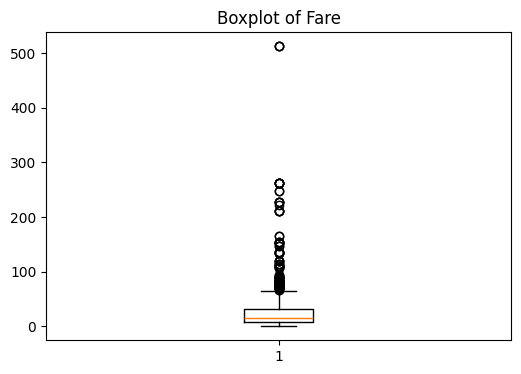

     PassengerId  Survived  Pclass  \
1              2         1       1   
27            28         0       1   
31            32         1       1   
34            35         0       1   
52            53         1       1   
..           ...       ...     ...   
846          847         0       3   
849          850         1       1   
856          857         1       1   
863          864         0       3   
879          880         1       1   

                                                  Name     Sex        Age  \
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.000000   
27                      Fortune, Mr. Charles Alexander    male  19.000000   
31      Spencer, Mrs. William Augustus (Marie Eugenie)  female  29.699118   
34                             Meyer, Mr. Edgar Joseph    male  28.000000   
52            Harper, Mrs. Henry Sleeper (Myna Haxtun)  female  49.000000   
..                                                 ...     ...        ...   
846 

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.boxplot(df["Fare"])

plt.title("Boxplot of Fare")

plt.show()

Q1 = df["Fare"].quantile(0.25)

Q3 = df["Fare"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

outliers = df[(df["Fare"] < lower) |
              (df["Fare"] > upper)]

print(outliers)

# Step 7: Handle Outliers

Remove outliers detected using the IQR method.

In [ ]:
df = df[(df["Fare"] >= lower) &
        (df["Fare"] <= upper)]

print(df.shape)

(775, 12)


# Step 8: Convert Categorical Variables

Convert categorical variables into numerical form using Label Encoding and One-Hot Encoding.

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Sex"] = le.fit_transform(df["Sex"])

df.head()

# and One-Hot Encoding.
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.000000,1,0,A/5 21171,7.2500,Unknown,0,0,1
2,3,1,3,"Heikkinen, Miss. Laina",0,26.000000,0,0,STON/O2. 3101282,7.9250,Unknown,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.000000,1,0,113803,53.1000,C123,0,0,1
4,5,0,3,"Allen, Mr. William Henry",1,35.000000,0,0,373450,8.0500,Unknown,0,0,1
5,6,0,3,"Moran, Mr. James",1,29.699118,0,0,330877,8.4583,Unknown,0,1,0


# Step 9: Feature Scaling

Apply Min-Max Normalization and Standardization.

In [ ]:
age_before_scaling = df["Age"].copy()

from sklearn.preprocessing import MinMaxScaler

mms = MinMaxScaler()

df["Age"] = mms.fit_transform(df[["Age"]])

df.head()

# and Standardization.
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

df["Fare"] = ss.fit_transform(df[["Fare"]])

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,0.271174,1,0,A/5 21171,-0.779117,Unknown,0,0,1
2,3,1,3,"Heikkinen, Miss. Laina",0,0.321438,0,0,STON/O2. 3101282,-0.729373,Unknown,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.434531,1,0,113803,2.599828,C123,0,0,1
4,5,0,3,"Allen, Mr. William Henry",1,0.434531,0,0,373450,-0.720161,Unknown,0,0,1
5,6,0,3,"Moran, Mr. James",1,0.367921,0,0,330877,-0.690071,Unknown,0,1,0


# Step 10: Feature Selection

Identify relevant attributes using correlation analysis.

In [ ]:
correlation = df.corr(numeric_only=True)

print(correlation["Survived"].sort_values(ascending=False))

Survived       1.000000
Fare           0.234422
Parch          0.098575
Embarked_C     0.096513
Embarked_Q     0.032707
SibSp         -0.003156
PassengerId   -0.024438
Embarked_S    -0.102337
Age           -0.121283
Pclass        -0.238532
Sex           -0.499888
Name: Survived, dtype: float64


# Step 11: Correlation Matrix

Generate and visualize the correlation matrix using a heatmap.

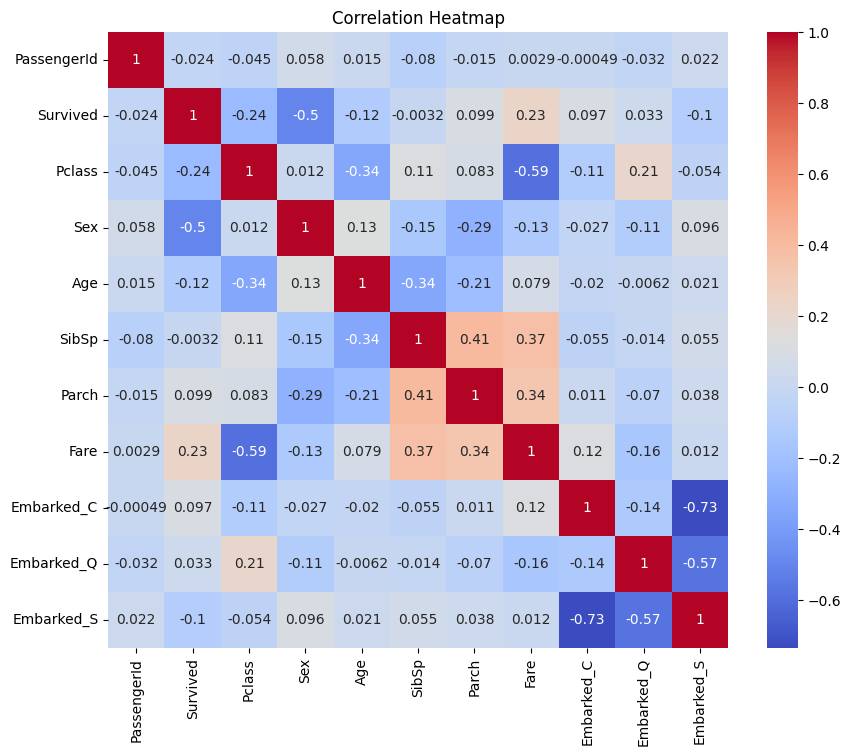

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

# Step 12: Feature Engineering

Create a new feature from existing attributes.

In [ ]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked_C,Embarked_Q,Embarked_S,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",1,0.271174,1,0,A/5 21171,-0.779117,Unknown,0,0,1,2
2,3,1,3,"Heikkinen, Miss. Laina",0,0.321438,0,0,STON/O2. 3101282,-0.729373,Unknown,0,0,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.434531,1,0,113803,2.599828,C123,0,0,1,2
4,5,0,3,"Allen, Mr. William Henry",1,0.434531,0,0,373450,-0.720161,Unknown,0,0,1,1
5,6,0,3,"Moran, Mr. James",1,0.367921,0,0,330877,-0.690071,Unknown,0,1,0,1


# Step 13: Data Type Conversion

Convert integer data type to float.

In [ ]:
df["PassengerId"] = df["PassengerId"].astype(float)

print(df.dtypes)

PassengerId    float64
Survived         int64
Pclass           int64
Name            object
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked_C       int64
Embarked_Q       int64
Embarked_S       int64
FamilySize       int64
dtype: object


# Step 14: Handle Inconsistent Data

Clean text data by removing extra spaces.

In [ ]:
df["Name"] = df["Name"].str.strip()

df["Ticket"] = df["Ticket"].str.strip()

df["Cabin"] = df["Cabin"].str.strip()

df.head()

# Convert names to Title Case
df["Name"] = df["Name"].str.title()

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked_C,Embarked_Q,Embarked_S,FamilySize
0,1.0,0,3,"Braund, Mr. Owen Harris",1,0.271174,1,0,A/5 21171,-0.779117,Unknown,0,0,1,2
2,3.0,1,3,"Heikkinen, Miss. Laina",0,0.321438,0,0,STON/O2. 3101282,-0.729373,Unknown,0,0,1,1
3,4.0,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.434531,1,0,113803,2.599828,C123,0,0,1,2
4,5.0,0,3,"Allen, Mr. William Henry",1,0.434531,0,0,373450,-0.720161,Unknown,0,0,1,1
5,6.0,0,3,"Moran, Mr. James",1,0.367921,0,0,330877,-0.690071,Unknown,0,1,0,1


# Step 15: Train-Test Split

Split the dataset into training and testing sets using Scikit-learn.

In [ ]:
from sklearn.model_selection import train_test_split

# Features
X = df.drop("Survived", axis=1)

# Convert remaining categorical columns to numeric
X = pd.get_dummies(X)

# Target
y = df["Survived"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (620, 1506)
Testing Data: (155, 1506)


# Step 16: Data Balancing

Balance the training dataset using SMOTE.

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE")
print(y_train.value_counts())

print("\nAfter SMOTE")
print(y_train_smote.value_counts())

Before SMOTE
Survived
0    417
1    203
Name: count, dtype: int64

After SMOTE
Survived
0    417
1    417
Name: count, dtype: int64


# Step 17: Distribution

Visualize the Age distribution before and after preprocessing.

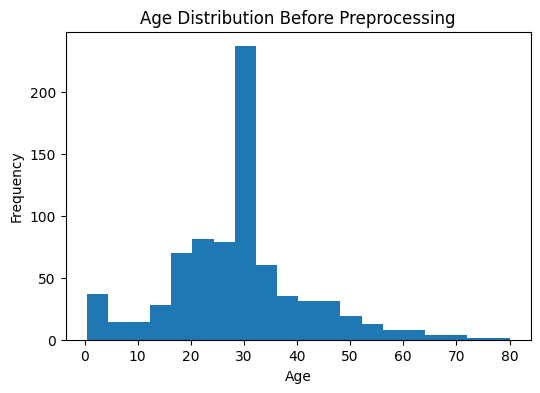

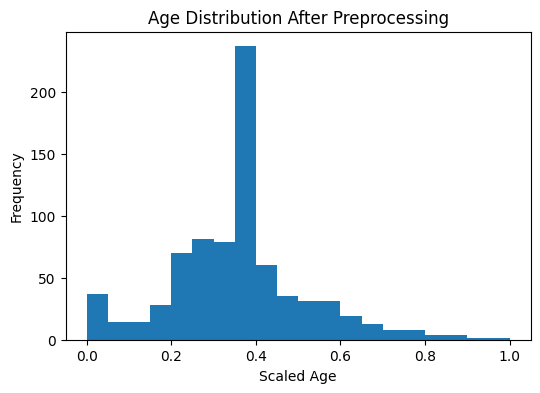

In [ ]:
import matplotlib.pyplot as plt

# Before preprocessing
plt.figure(figsize=(6,4))
plt.hist(age_before_scaling, bins=20)
plt.title("Age Distribution Before Preprocessing")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# After preprocessing
plt.figure(figsize=(6,4))
plt.hist(df["Age"], bins=20)
plt.title("Age Distribution After Preprocessing")
plt.xlabel("Scaled Age")
plt.ylabel("Frequency")
plt.show()

# Step 18: Comparison

Summarize the preprocessing steps performed.

In [ ]:
print("Final Dataset Shape:", df.shape)

print("\nFirst Five Rows")

display(df.head())

print("\nColumn Names")

print(df.columns.tolist())

Final Dataset Shape: (775, 15)

First Five Rows


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked_C,Embarked_Q,Embarked_S,FamilySize
0,1.0,0,3,"Braund, Mr. Owen Harris",1,0.271174,1,0,A/5 21171,-0.779117,Unknown,0,0,1,2
2,3.0,1,3,"Heikkinen, Miss. Laina",0,0.321438,0,0,STON/O2. 3101282,-0.729373,Unknown,0,0,1,1
3,4.0,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.434531,1,0,113803,2.599828,C123,0,0,1,2
4,5.0,0,3,"Allen, Mr. William Henry",1,0.434531,0,0,373450,-0.720161,Unknown,0,0,1,1
5,6.0,0,3,"Moran, Mr. James",1,0.367921,0,0,330877,-0.690071,Unknown,0,1,0,1



Column Names
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'FamilySize']


# Step 19: Save Dataset

Save the cleaned dataset as a CSV file.

In [ ]:
df.to_csv("Titanic_Cleaned.csv", index=False)

print("Dataset Saved Successfully!")

from google.colab import files

files.download("Titanic_Cleaned.csv")

Dataset Saved Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# Step 20: Documentation

The following preprocessing steps were performed:

1. Loaded the dataset.
2. Displayed dataset information.
3. Inspected records.
4. Handled missing values.
5. Removed duplicate records.
6. Detected outliers.
7. Removed outliers.
8. Applied Label Encoding and One-Hot Encoding.
9. Performed Min-Max Normalization and Standardization.
10. Selected relevant features using correlation.
11. Generated correlation matrix and heatmap.
12. Created FamilySize feature.
13. Converted PassengerId to float.
14. Cleaned inconsistent text data.
15. Split the dataset into training and testing sets.
16. Balanced the training data using SMOTE.
17. Visualized data distribution.
18. Compared the dataset before and after preprocessing.
19. Saved the cleaned dataset.
20. Documented all preprocessing steps.

## Step 21: Implement Linear Regression

Implement a Linear Regression model, train it on the preprocessed training data, and evaluate its performance on the test set.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize and train the Linear Regression model
linear_reg_model = LinearRegression()
linear_reg_model.fit(X_train_smote, y_train_smote)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [ ]:
# Make predictions on the test set
y_pred_linear_reg = linear_reg_model.predict(X_test)

# Round predictions to 0 or 1 for classification context
y_pred_linear_reg_binary = (y_pred_linear_reg > 0.5).astype(int)

print("Predictions made successfully.")

Predictions made successfully.


In [ ]:
# Evaluate the model
mae_linear_reg = mean_absolute_error(y_test, y_pred_linear_reg_binary)
mse_linear_reg = mean_squared_error(y_test, y_pred_linear_reg_binary)
r2_linear_reg = r2_score(y_test, y_pred_linear_reg_binary)

print(f"Mean Absolute Error (MAE): {mae_linear_reg:.4f}")
print(f"Mean Squared Error (MSE): {mse_linear_reg:.4f}")
print(f"R-squared (R2) Score: {r2_linear_reg:.4f}")

Mean Absolute Error (MAE): 0.5548
Mean Squared Error (MSE): 0.5548
R-squared (R2) Score: -1.3386


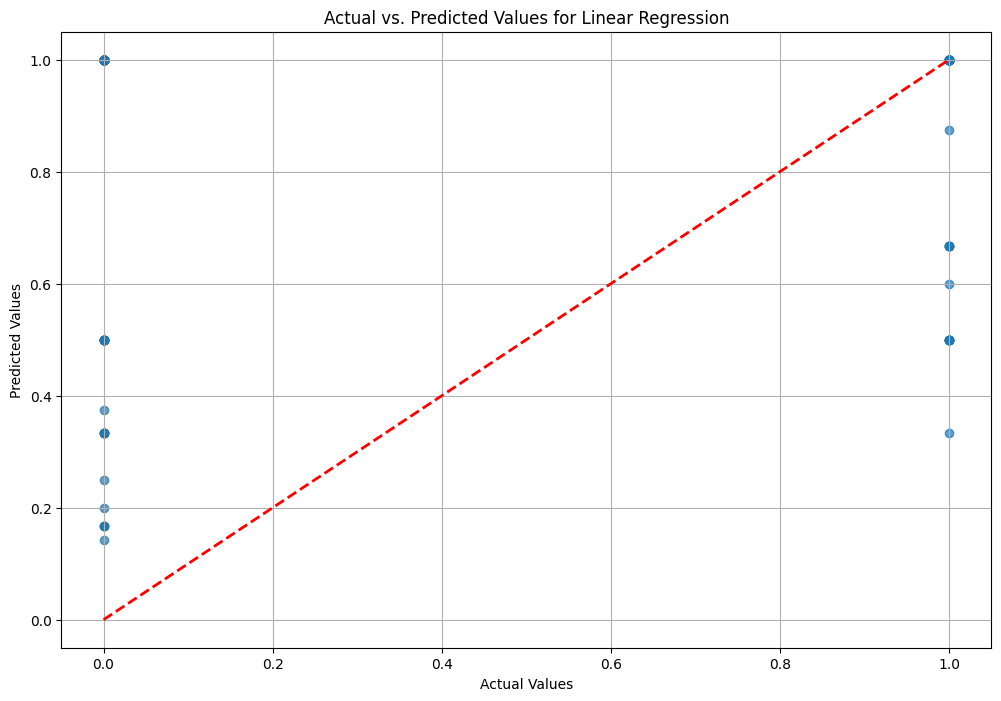

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.scatter(y_test, y_pred_linear_reg, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values for Linear Regression')
plt.grid(True)
plt.show()

### Multi-value Linear Regression (Already Implemented)

The `linear_reg_model` we trained in `cell_mzHu9s7vQvSy` is a multi-value (or multiple) linear regression model. It utilized all the preprocessed and engineered features (like `Age`, `Sex`, `Pclass`, `Fare`, `Embarked` dummies, `FamilySize`, etc.) from our dataset to predict the `Survived` status.

Its evaluation metrics were:
*   Mean Absolute Error (MAE): 0.5548
*   Mean Squared Error (MSE): 0.5548
*   R-squared (R2) Score: -1.3386

And the scatter plot above (Actual vs. Predicted Values) visualizes its predictions.

### Single-value Linear Regression (using 'Fare')

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for single-value regression using 'Fare'
X_single_feature = df[['Fare']]
y_single_feature = df['Survived']

# Split the dataset for single feature
X_train_single, X_test_single, y_train_single, y_test_single = train_test_split(
    X_single_feature,
    y_single_feature,
    test_size=0.2,
    random_state=42
)

# Apply SMOTE to balance the training data for the single feature
smote_single = SMOTE(random_state=42)
X_train_single_smote, y_train_single_smote = smote_single.fit_resample(
    X_train_single,
    y_train_single
)

print("Single-feature training data balanced with SMOTE.")

# Initialize and train the Linear Regression model with a single feature
linear_reg_single_model = LinearRegression()
linear_reg_single_model.fit(X_train_single_smote, y_train_single_smote)

print("Single-value Linear Regression model trained successfully using 'Fare'.")

Single-feature training data balanced with SMOTE.
Single-value Linear Regression model trained successfully using 'Fare'.


In [ ]:
# Make predictions on the test set for the single feature model
y_pred_single_reg = linear_reg_single_model.predict(X_test_single)

# Round predictions to 0 or 1 for classification context
y_pred_single_reg_binary = (y_pred_single_reg > 0.5).astype(int)

# Evaluate the single feature model
mae_single_reg = mean_absolute_error(y_test_single, y_pred_single_reg_binary)
mse_single_reg = mean_squared_error(y_test_single, y_pred_single_reg_binary)
r2_single_reg = r2_score(y_test_single, y_pred_single_reg_binary)

print(f"\nSingle-Value Linear Regression Model Evaluation (using 'Fare'):")
print(f"Mean Absolute Error (MAE): {mae_single_reg:.4f}")
print(f"Mean Squared Error (MSE): {mse_single_reg:.4f}")
print(f"R-squared (R2) Score: {r2_single_reg:.4f}")


Single-Value Linear Regression Model Evaluation (using 'Fare'):
Mean Absolute Error (MAE): 0.3806
Mean Squared Error (MSE): 0.3806
R-squared (R2) Score: -0.6044


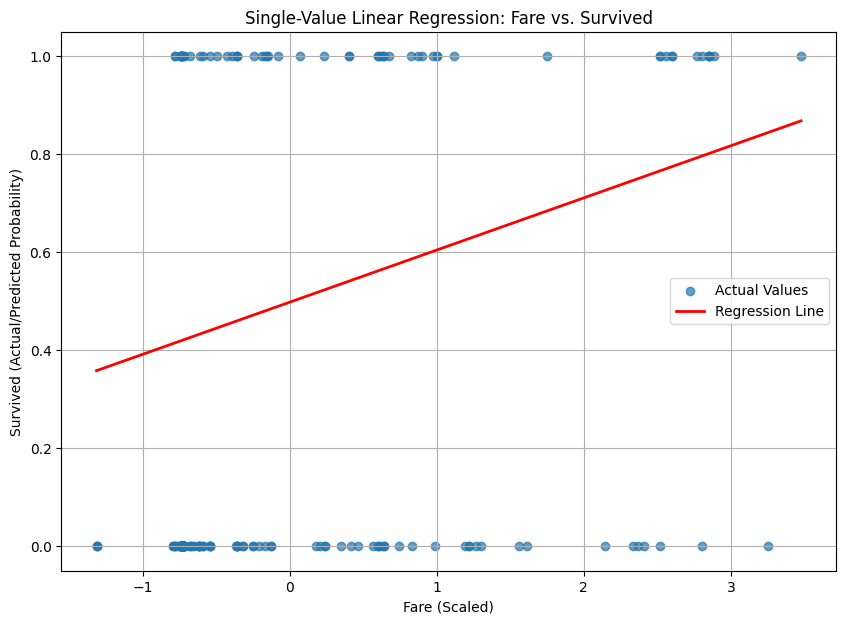

In [ ]:
# Plotting for Single-Value Linear Regression (Fare vs. Survived)

plt.figure(figsize=(10, 7))
plt.scatter(X_test_single['Fare'], y_test_single, alpha=0.7, label='Actual Values')

# Plot the regression line
# For better visualization, sort the X_test_single values
sorted_idx = np.argsort(X_test_single['Fare'])
plt.plot(X_test_single['Fare'].iloc[sorted_idx], y_pred_single_reg[sorted_idx], color='red', linewidth=2, label='Regression Line')

plt.xlabel('Fare (Scaled)')
plt.ylabel('Survived (Actual/Predicted Probability)')
plt.title('Single-Value Linear Regression: Fare vs. Survived')
plt.grid(True)
plt.legend()
plt.show()

## A* Search Algorithm Implementation

Below is a Python implementation of the A* algorithm. It uses a priority queue to efficiently explore paths, prioritizing those with the lowest estimated total cost (g-cost + h-cost).


In [ ]:
import heapq

def a_star_search(graph, start, goal, heuristic):
    # Priority queue stores (f_cost, current_g_cost, current_node, path)
    # f_cost = g_cost + h_cost
    priority_queue = [(0 + heuristic[start], 0, start, [start])]

    # Dictionary to store the minimum g_cost to reach each node found so far
    g_costs = {start: 0}

    while priority_queue:
        f_cost, current_g_cost, current_node, path = heapq.heappop(priority_queue)

        # If we reached the goal, return the path and its cost
        if current_node == goal:
            return path, current_g_cost

        # If we found a cheaper path to this node, skip it (already processed)
        if current_g_cost > g_costs.get(current_node, float('inf')):
            continue

        # Explore neighbors
        for neighbor, cost_to_neighbor in graph.get(current_node, []):
            new_g_cost = current_g_cost + cost_to_neighbor

            # If this new path to the neighbor is shorter (or new)
            if new_g_cost < g_costs.get(neighbor, float('inf')):
                g_costs[neighbor] = new_g_cost
                new_f_cost = new_g_cost + heuristic[neighbor]
                new_path = path + [neighbor]
                heapq.heappush(priority_queue, (new_f_cost, new_g_cost, neighbor, new_path))

    return None, float('inf') # No path found

# Define a sample graph (adjacency list: node -> [(neighbor, cost)])
graph_astar = {
    'A': [('B', 1), ('C', 3)],
    'B': [('D', 3), ('E', 2)],
    'C': [('D', 1)],
    'D': [('F', 2)],
    'E': [('F', 4)]
}

# Define a heuristic (estimated straight-line distance to goal 'F')
heuristic_astar = {
    'A': 6,
    'B': 4,
    'C': 2,
    'D': 1,
    'E': 3,
    'F': 0  # Goal has a heuristic of 0
}

start_node_astar = 'A'
goal_node_astar = 'F'

path_astar, cost_astar = a_star_search(graph_astar, start_node_astar, goal_node_astar, heuristic_astar)

if path_astar:
    print(f"A* Search: Path from {start_node_astar} to {goal_node_astar}: {path_astar}")
    print(f"A* Search: Total cost: {cost_astar}")
else:
    print(f"A* Search: No path found from {start_node_astar} to {goal_node_astar}")


A* Search: Path from A to F: ['A', 'B', 'D', 'F']
A* Search: Total cost: 6


## Uniform Cost Search (UCS) Algorithm Implementation

Here is a Python implementation of the Uniform Cost Search (UCS) algorithm. UCS is similar to Dijkstra's algorithm and explores paths by always expanding the node that has the lowest total cost from the starting point, without using a heuristic.

### Example Graph:

We'll use the same graph structure as for A* to demonstrate UCS.

In [ ]:
import heapq

def ucs_search(graph, start, goal):
    # Priority queue stores (cost, current_node, path)
    priority_queue = [(0, start, [start])]

    # Dictionary to store the minimum cost to reach each node found so far
    costs = {start: 0}

    while priority_queue:
        current_cost, current_node, path = heapq.heappop(priority_queue)

        # If we reached the goal, return the path and its cost
        if current_node == goal:
            return path, current_cost

        # If we found a cheaper path to this node, skip it (already processed)
        if current_cost > costs.get(current_node, float('inf')):
            continue

        # Explore neighbors
        for neighbor, cost_to_neighbor in graph.get(current_node, []):
            new_cost = current_cost + cost_to_neighbor

            # If this new path to the neighbor is shorter (or new)
            if new_cost < costs.get(neighbor, float('inf')):
                costs[neighbor] = new_cost
                new_path = path + [neighbor]
                heapq.heappush(priority_queue, (new_cost, neighbor, new_path))

    return None, float('inf') # No path found

# Using the same sample graph defined for A*
graph_ucs = {
    'A': [('B', 1), ('C', 3)],
    'B': [('D', 3), ('E', 2)],
    'C': [('D', 1)],
    'D': [('F', 2)],
    'E': [('F', 4)]
}

start_node_ucs = 'A'
goal_node_ucs = 'F'

path_ucs, cost_ucs = ucs_search(graph_ucs, start_node_ucs, goal_node_ucs)

if path_ucs:
    print(f"UCS Search: Path from {start_node_ucs} to {goal_node_ucs}: {path_ucs}")
    print(f"UCS Search: Total cost: {cost_ucs}")
else:
    print(f"UCS Search: No path found from {start_node_ucs} to {goal_node_ucs}")


UCS Search: Path from A to F: ['A', 'B', 'D', 'F']
UCS Search: Total cost: 6


## Greedy Best-First Search (GBFS) Implementation

This implementation uses a priority queue, similar to A*, but only considers the heuristic cost (`h-cost`) to prioritize nodes.

In [ ]:
import heapq

def gbfs_search(graph, start, goal, heuristic):
    # Priority queue stores (h_cost, current_node, path)
    priority_queue = [(heuristic[start], start, [start])]

    # Set to keep track of visited nodes to avoid cycles
    visited = set()

    while priority_queue:
        h_cost, current_node, path = heapq.heappop(priority_queue)

        if current_node == goal:
            return path

        if current_node in visited:
            continue

        visited.add(current_node)

        for neighbor, _ in graph.get(current_node, []): # GBFS ignores actual edge costs
            if neighbor not in visited:
                new_path = path + [neighbor]
                heapq.heappush(priority_queue, (heuristic[neighbor], neighbor, new_path))

    return None # No path found

# Using the same graph structure as before, but GBFS will only use the heuristic
graph_gbfs = {
    'A': [('B', 1), ('C', 3)],
    'B': [('D', 3), ('E', 2)],
    'C': [('D', 1)],
    'D': [('F', 2)],
    'E': [('F', 4)]
}

# Heuristic (estimated straight-line distance to goal 'F')
heuristic_gbfs = {
    'A': 6,
    'B': 4,
    'C': 2,
    'D': 1,
    'E': 3,
    'F': 0
}

start_node_gbfs = 'A'
goal_node_gbfs = 'F'

path_gbfs = gbfs_search(graph_gbfs, start_node_gbfs, goal_node_gbfs, heuristic_gbfs)

if path_gbfs:
    print(f"Greedy Best-First Search: Path from {start_node_gbfs} to {goal_node_gbfs}: {path_gbfs}")
else:
    print(f"Greedy Best-First Search: No path found from {start_node_gbfs} to {goal_node_gbfs}")


Greedy Best-First Search: Path from A to F: ['A', 'C', 'D', 'F']


## Depth-First Search (DFS) Implementation

DFS explores as deeply as possible along each branch before backtracking. It typically uses a stack.

In [ ]:
def dfs_search(graph, start, goal):
    stack = [(start, [start])] # Stack stores (current_node, path)
    visited = set() # Set to keep track of visited nodes

    while stack:
        current_node, path = stack.pop() # Pop from the top (LIFO)

        if current_node == goal:
            return path

        if current_node in visited:
            continue

        visited.add(current_node)

        # Explore neighbors (reversing to push in natural order if needed, but not critical for correctness)
        for neighbor, _ in reversed(graph.get(current_node, [])): # Reverse to explore in a consistent order
            if neighbor not in visited:
                new_path = path + [neighbor]
                stack.append((neighbor, new_path))

    return None # No path found

# Using the same simple graph structure (costs are ignored by DFS/BFS for pathfinding)
graph_dfs = {
    'A': [('B', 1), ('C', 3)],
    'B': [('D', 3), ('E', 2)],
    'C': [('D', 1)],
    'D': [('F', 2)],
    'E': [('F', 4)]
}

start_node_dfs = 'A'
goal_node_dfs = 'F'

path_dfs = dfs_search(graph_dfs, start_node_dfs, goal_node_dfs)

if path_dfs:
    print(f"Depth-First Search: Path from {start_node_dfs} to {goal_node_dfs}: {path_dfs}")
else:
    print(f"Depth-First Search: No path found from {start_node_dfs} to {goal_node_dfs}")


Depth-First Search: Path from A to F: ['A', 'B', 'D', 'F']


## Breadth-First Search (BFS) Implementation

BFS explores all neighbors at the current depth before moving to the next depth level. It typically uses a queue.

In [ ]:
from collections import deque

def bfs_search(graph, start, goal):
    queue = deque([(start, [start])]) # Queue stores (current_node, path)
    visited = set() # Set to keep track of visited nodes

    visited.add(start)

    while queue:
        current_node, path = queue.popleft() # Pop from the left (FIFO)

        if current_node == goal:
            return path

        for neighbor, _ in graph.get(current_node, []):
            if neighbor not in visited:
                visited.add(neighbor)
                new_path = path + [neighbor]
                queue.append((neighbor, new_path))

    return None # No path found

# Using the same simple graph structure (costs are ignored by DFS/BFS for pathfinding)
graph_bfs = {
    'A': [('B', 1), ('C', 3)],
    'B': [('D', 3), ('E', 2)],
    'C': [('D', 1)],
    'D': [('F', 2)],
    'E': [('F', 4)]
}

start_node_bfs = 'A'
goal_node_bfs = 'F'

path_bfs = bfs_search(graph_bfs, start_node_bfs, goal_node_bfs)

if path_bfs:
    print(f"Breadth-First Search: Path from {start_node_bfs} to {goal_node_bfs}: {path_bfs}")
else:
    print(f"Breadth-First Search: No path found from {start_node_bfs} to {goal_node_bfs}")


Breadth-First Search: Path from A to F: ['A', 'B', 'D', 'F']
